# Week 1 — Mini Project 1
## Numerical Pattern Predictor

**Goal:** Train a neural network to learn a simple numerical pattern and predict outputs for unseen inputs.

## 1. Import libraries

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## 2. Generate data
The pattern is approximately **y = 2x + 1** with a little noise.

In [2]:
x = torch.linspace(0, 10, 120).reshape(-1, 1)
y = 2 * x + 1 + 0.2 * torch.randn_like(x)
train_end = int(0.80 * len(x))
x_train, y_train = x[:train_end], y[:train_end]
x_test, y_test = x[train_end:], y[train_end:]
print('Training examples:', len(x_train))
print('Unseen test examples:', len(x_test))

Training examples: 96
Unseen test examples: 24


## 3. Build and train the model

In [3]:
class PatternNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1))
    def forward(self, x):
        return self.layers(x)

model = PatternNet()
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
losses = []
for epoch in range(200):
    model.train()
    prediction = model(x_train)
    loss = loss_fn(prediction, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print('Final training loss:', round(losses[-1], 4))

Final training loss: 0.0423


## 4. Plot the loss curve

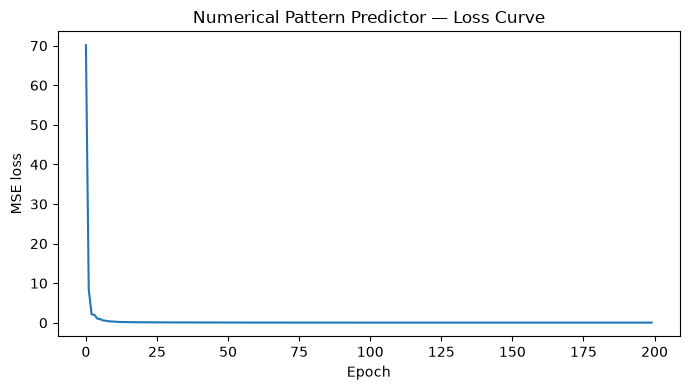

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.title('Numerical Pattern Predictor — Loss Curve')
plt.tight_layout()
plt.show()

## 5. Compare actual and predicted values on unseen data

First 5 actual values: [16.6299991607666, 17.399999618530273, 17.6299991607666, 17.639999389648438, 17.93000030517578]
First 5 predictions: [17.059999465942383, 17.229999542236328, 17.389999389648438, 17.549999237060547, 17.719999313354492]


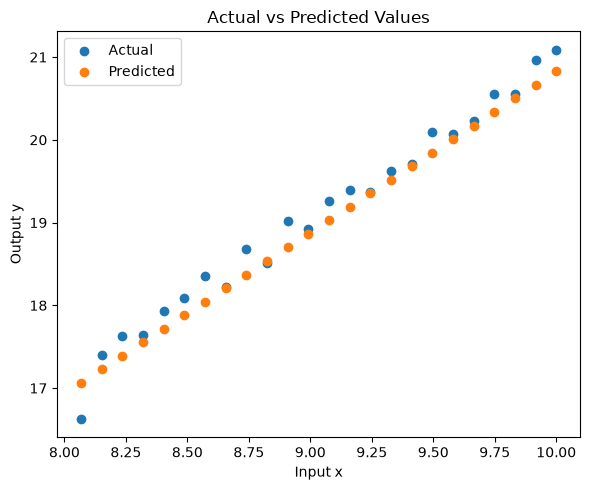

In [5]:
model.eval()
with torch.no_grad():
    predicted = model(x_test)
print('First 5 actual values:', y_test[:5].flatten().round(decimals=2).tolist())
print('First 5 predictions:', predicted[:5].flatten().round(decimals=2).tolist())
plt.figure(figsize=(6, 5))
plt.scatter(x_test.numpy(), y_test.numpy(), label='Actual')
plt.scatter(x_test.numpy(), predicted.numpy(), label='Predicted')
plt.xlabel('Input x')
plt.ylabel('Output y')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Try a new input

In [6]:
new_x = torch.tensor([[8.5]])
with torch.no_grad():
    new_prediction = model(new_x).item()
print(f'Input: {new_x.item()} | Predicted output: {new_prediction:.2f}')

Input: 8.5 | Predicted output: 17.91


## 7. Short explanation
The model learns the relationship between inputs and outputs from generated examples. After training, it predicts outputs for inputs it did not train on. The loss curve shows how prediction error changes during training, and the actual-versus-predicted graph shows how close the predictions are to the real values.

**Simple presentation:** “I created data following the pattern y = 2x + 1 and trained a small neural network using PyTorch. I tested it on unseen numbers and plotted the loss curve and actual-versus-predicted values.”